In [1]:
"""
This is the code for assignment 9. It uses the Adult dataset,
which contains data from the 1994 cencus database.
"""

# Question 1: Preprocessing

import pandas as pd
from sklearn.preprocessing import LabelEncoder
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import f_oneway

# Adding column names manually since the data doesn't come with them.
adult_df = pd.read_csv("adult.data",
                       names=["age", "workclass", "fnlwgt",
                              "education", "education_num",
                              "marital_status", "occupation",
                              "relationship", "race", "sex", "capital_gain",
                              "capital_loss", "hours_per_week",
                              "native_country", "income"])

# Below, I perform all preprocessing steps on the "workclass" column,
# chosen in part because it had missing data to deal with.

def strip_whitespace (col: pd.Series):
    """
    This function strips whitespaces from a column to
    normalize/standardize its values.
    
    Input: column from adult_df.
    
    Returns: column with stripped whitespaces.
    """

    stripped = col.str.strip()

    return stripped

# Calling strip_whitespace for all columns, skipping over ones
# that would raise an AttributeError.

for column in adult_df:
    try:
        adult_df[column] = strip_whitespace(adult_df[column])
    except AttributeError:
        continue

def preprocess_missing (col: pd.Series):
    """
    This function was built to handle missing values in a column.

    input: column from a DataFrame, which is also a series.

    returns: preprocessed version of that column.
    """
    # Fills null values with "Missing"
    processed = col.fillna("Missing")
    # Replaces ?s with "Missing" since that's how this dataset handled
    # missing values originally.
    processed = col.replace("?", "Missing")

    return processed

# Calling preprocess_missing function for all columns.

for cols in adult_df:
    adult_df[cols] = preprocess_missing(adult_df[cols])

def cat_to_num (col: pd.Series):
    """
    This function converts a categorical column to a numerical one.

    Input: a column from adult_df.

    Returns: a new column with numeric values taken from the
    input column.
    """
    # Uses label encoder to make new numeric column
    class_labels = LabelEncoder()
    numeric = class_labels.fit_transform(col)

    return numeric

adult_df["workclass_modified"] = cat_to_num(adult_df["workclass"])

def onehot (df: pd.DataFrame, col: str):
    """
    This function performs one-hot encoding on categorical columns.

    input: the adult_df DataFrame (df) and the name of the column
    you wish to one-hot encode as a str (col).

    returns: dataframe with one-hot encoding.
    """
    hot = pd.get_dummies(df, columns=[col])

    return hot

adult_df = onehot(adult_df, "workclass")

def drop_col (df: pd.DataFrame, col: str):
    """
    This function will drop a column from a dataframe. After
    doing the one-hot encoding, we have introduced multicollinearity.
    Since one one-hot column per row will always be true, you can
    remove one of those columns, since if all others are False,
    you know what the only remaining option is without the need
    for a specific column.
    
    Input: adult_df dataframe (df) and the name of the column to drop
    as a string (col).
    
    Returns: DataFrame with specified column dropped.
    """

    dropped = df.drop(columns=col)

    return dropped

# Dropping the "missing" column since if all the other one-hot workclass
# columns are False, the true value must be missing. This addresses
# multicollinearity caused by One Hot encoding.
adult_df = drop_col(adult_df, "workclass_Missing")

adult_df.to_csv("output_adult.csv")

# Gen AI used to count null/? values left.
# In below lines, the first sum adds totals per column, and the
# second sum adds column totals for a grand total.
null_count = adult_df.isnull().sum().sum()
count = (adult_df == "?").sum().sum()

print(f"There are {null_count} null values and {count} ? values remaining after preprocessing.")

There are 0 null values and 0 ? values remaining after preprocessing.


In [2]:
class Preprocessing:
    """
    This class will store the different preprocessing
    steps as objects containing definitions.
    """
    def __init__(self, step):
        self.step = step

    def definition(self, defin):
        """Allows objects to have definitions."""
        self.defin = defin

    def define(self):
        """Returns the definition for each object."""
        return f"{self.step}: {self.defin}."

# I didn't recall which steps we didn't cover, so I defined them all.

step1 = Preprocessing("Cleaning up null values")
step2 = Preprocessing("Data cleaning")
step3 = Preprocessing("One-hot encoding")
step4 = Preprocessing("Convert categorical values to numerical")
step5 = Preprocessing("Standardization/Normalization")
step6 = Preprocessing("Deal with multicollinearity")

step1.definition("Replacing null values in the dataset with an indicator of a " \
"missing value, a central tendency, or some other value that makes sense")
step2.definition("Handling missing data not dealt with in prior step, and removing " \
"extreme outliers if it makes sense for the data and the analysis")
step3.definition("Converting categorical data into a boolean format to be more" \
"easily processed")
step4.definition("Converting categorical data into a numerical format (if it's all a " \
"0 or 1, this would be the same as the prior step) to be more easily processed")
step5.definition("Converting values into the same format for consistency")
step6.definition("If multicollinearity exists (i.e., one column can be exactly "
"or near-exactly predicted by others), consider removing redundant data")

print(step1.define())
print(step2.define())
print(step3.define())
print(step4.define())
print(step5.define())
print(step6.define())

Cleaning up null values: Replacing null values in the dataset with an indicator of a missing value, a central tendency, or some other value that makes sense.
Data cleaning: Handling missing data not dealt with in prior step, and removing extreme outliers if it makes sense for the data and the analysis.
One-hot encoding: Converting categorical data into a boolean format to be moreeasily processed.
Convert categorical values to numerical: Converting categorical data into a numerical format (if it's all a 0 or 1, this would be the same as the prior step) to be more easily processed.
Standardization/Normalization: Converting values into the same format for consistency.
Deal with multicollinearity: If multicollinearity exists (i.e., one column can be exactly or near-exactly predicted by others), consider removing redundant data.


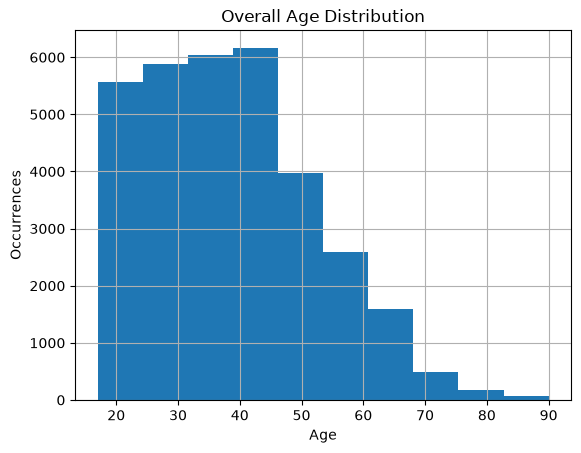

In [3]:
# Question 2: Visuals

def histogram (col: pd.Series, xlabel: str, ylabel: str, title: str):
    """
    This function creates a histogram of an input column.
    
    Input: adult_df column (col), x and y-axis labels, and the chart title.
    
    Returns: histogram
    """
    col.hist()

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)

    return plt.show()

histogram(adult_df["age"], "Age", "Occurrences", "Overall Age Distribution")

## Age Histogram:

The above cell creates a histogram showing the distribution of the age variable. This shows that the data is very right-skewed. This makes sense, since birth rates tend to rise over time as populations increase, we would expect to see more young people than old people. This skewness drags the median and mean further to the right, while the mode stays at the peak of the distribution (around 40).

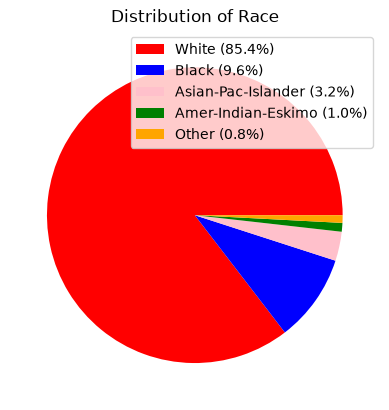

In [4]:
def pie (col: pd.Series, color_list: list, title: str):
    """
    This makes a pie chart for a given column.
    
    Input: column from adult_df (col), list of colors to use
    (color_list), and a title for the chart.
    
    Returns: Pie chart for input column.
    """
    # Gen AI used to see how to get percentages inside a legend, since the ones
    # on the slices were too close together. First we get the count of the
    # values in the column, then make the plot, then make the "labels" variable.
    counts = col.value_counts()
    counts.plot(kind="pie", colors=color_list,
                            labels=None)
    # This takes the category names, calculates the % of the total, rounds to 1
    # decimal place, makes it a string, and adds a percent sign.
    labels = counts.index+" ("+(counts / counts.sum()*100).round(1).astype(str)+"%)"
    plt.legend(labels)
    plt.title(title)

    return plt.show()

pie(adult_df["race"], ["red", "blue", "pink", "green", "orange"], "Distribution of Race")

## Pie Chart of Race

The above cell creates a pie chart of the race variable for the dataset. It shows that the vast majority of people listed are white, with a small mix of other races. This means that it would be tricky to compare aggregate variables of different races, since we have so much more data for whites. This is because the Law of Large numbers will make the mean of variables grouped by whites more likely to be close to the true population mean than the mean of variables grouped by other races.

This also shows why pie charts tend to be looked down upon. It's easy to see that white makes up the bulk of the pie chart, but as the slices get smaller, it's harder and harder to compare their sizes.

Education Level meanings:
1: Preschool
2: Grade 1-4
3: Grade 5-6
4: Grade 7-8
5: Grade 9
6: Grade 10
7: Grade 11
8: Grade 12
9: HS Graduate
10: Some college
11: Associate's (Vocational)
12: Associate's (Academic)
13: Bachelor's
14: Master's
15: Professional Degree
16: Doctorate


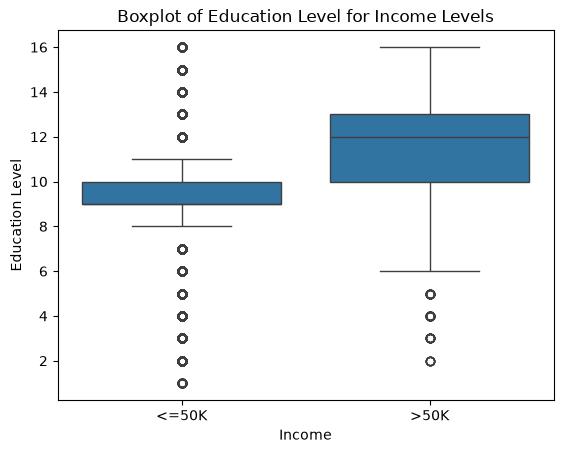

In [5]:
def boxplot (df: pd.DataFrame, xa: pd.Series, ya: pd.Series,
             xlabel: str, ylabel: str, title: str):
    """
    This function creates side-by-side box plots of two
    columns in a dataframe.
    
    Input: adult_df (df), x-axis column (xa), y-axis column (ya),
    x and y-axis labels (xlabel & ylabel), and chart title (title).
    
    Returns: Side-by-side box plot.
    """

    sns.boxplot(data = df, x = xa, y = ya)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)

    return plt.show()

# Printing meanings of educational levels.
print("Education Level meanings:\n1: Preschool\n2: Grade 1-4\n3: Grade 5-6" \
"\n4: Grade 7-8\n5: Grade 9\n6: Grade 10\n7: Grade 11\n8: Grade 12\n9: HS Graduate" \
"\n10: Some college\n11: Associate's (Vocational)\n12: Associate's (Academic)" \
"\n13: Bachelor's\n14: Master's\n15: Professional Degree\n16: Doctorate")

boxplot(adult_df, adult_df["income"], adult_df["education_num"], "Income",
        "Education Level", "Boxplot of Education Level for Income Levels")

## Box Plots of Education Level and Income

The above cell creates two side-by-side box plots, one for the educational levels of people with income less than or equal to $50,000, and one for educational levels of people with income above $50,000. It shows a much narrower spread of education for people with lower income, with the median hovering somewhere around 9 (HS Graduate) but there are some outliers far above and far below the median. For the box plot of higher income people, there's more spread and a higher median, around 12 (Academic Associate's degree, as opposed to a vocational one). The only outliers for the higher-income box plot are below the minimum, since the maximum goes all the way up to the max level of education. From this, we can infer that higher education is likely correlated with higher incomes.

In [6]:
# Question 3: ANOVA

# At the 0.05 level of significance:
# Null hypothesis: in the adult_df dataset, there is no difference between
# the mean education level of people with incomes <= $50,000 and > $50,000.
# Alternative hypothesis: in the adult_df dataset, there is a difference between
# the mean education level of people with incomes <= $50,000 and > $50,000.

def high_level_stats (df: pd.DataFrame, col1: str, col2: str):
    """
    This function outputs high-level statistics to compare with the
    ANOVA results from the next function.
    
    Input: adult_df dataframe (df) and the two columns to be compared
    (col1 & col2).
    
    Returns: table showing mean, std deviation, and count.
    """
    # This calculates sampe standard deviation by default, so no need
    # to change it. This is a sample because the census doesn't have
    # data on EVERY single person in its scope, as much as it tries.
    table = df.groupby(col1)[col2].agg(["mean", "std", "count"])

    return table

print(high_level_stats(adult_df, "income", "education_num"))

def anova (df: pd.DataFrame, col1: str, col2: str, col1_group1: str, col1_group2: str):
    """
    This function performs a one-way ANOVA.
    
    Input: adult_df dataframe (df), the names of the
    two columns in the ANOVA (col1 & col2), and the categories
    of column 1 by which to group the second column (col1_group1
    and col1_group2).
    
    Returns: the F-statistic and p-value.
    """

    over_50 = df.loc[df[col1] == col1_group1, col2]
    under_50 = df.loc[df[col1] == col1_group2, col2]

    return f_oneway(over_50, under_50)

f, p = anova(adult_df, "income", "education_num", ">50K", "<=50K")
# Checks if p-value is zero, which is technically impossible. If so, clarifies
# that it's just a really small number.
if p == 0:
    p = "less than 0.001"

print(f"\nThe F-statistic is {f} and the p-value is {p}.")

             mean       std  count
income                            
<=50K    9.595065  2.436147  24720
>50K    11.611657  2.385129   7841

The F-statistic is 4120.095779707476 and the p-value is less than 0.001.


## Interpreting One-Way ANOVA

The above cell calculates the F-statistic and p-value for my one-way ANOVA. It originally returned a p-value of 0, which is technically impossible, but Gen AI explained that this is due to a floating point underrun (i.e., the number is so small it's rounded to 0). I also learned that when this occurs, it's standard practice to say the p-value is less than 0.001, so I added an If statement in the code to do this.

Since my F-statistic was large and my p-value was far below my outlined level of significance at 0.05, I can *reject* my null hypothesis that there is no difference between the mean levels of education for people with incomes above and below/equal to $50,000.

## Pylint Score: 86.6%

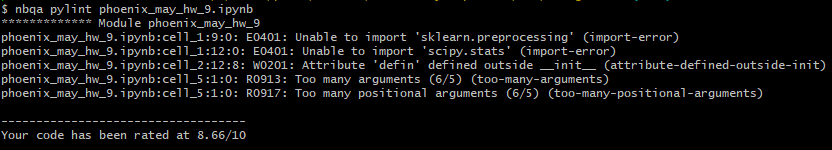